In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Dataset එක කෙලින්ම String එකක් ලෙස Embed කිරීම
csv_data = """Team,Current_Rank,Total_Matches,Total_Wins,Total_Losses,Total_Tie_NR,Win_Percentage,2007_W,2007_L,2007_Tie_NR,2011_W,2011_L,2011_Tie_NR,2015_W,2015_L,2015_Tie_NR,2019_W,2019_L,2019_Tie_NR,2023_W,2023_L,2023_Tie_NR,SA_Tour_Last5Y_Matches,SA_Tour_Last5Y_W,SA_Tour_Last5Y_L,SA_Tour_Last5Y_NR,SA_Tour_Last5Y_Win_Pct,Title_Or_Best_Finish
India,1,41,32,7,2,78.05,1,2,0,7,1,1,7,1,0,7,2,1,10,1,0,6,2,4,0,33.33,Champions (2011)
Australia,2,48,38,8,2,79.17,11,0,0,4,2,1,7,1,1,7,3,0,9,2,0,5,2,3,0,40.00,Champions (2007; 2015; 2023)
South_Africa,3,45,28,16,1,62.22,7,3,0,5,2,0,6,3,0,3,5,1,7,3,0,23,12,10,1,52.17,Semi-Finals (2007; 2015; 2023)
Pakistan,4,36,20,15,1,55.56,1,2,0,6,2,0,4,3,0,5,3,1,4,5,0,3,2,1,0,66.67,Semi-Finals (2011)
New_Zealand,5,48,31,16,1,64.58,7,3,0,6,3,0,8,1,0,5,4,1,5,5,0,null,null,null,null,null,Runners-up (2015; 2019)
Sri_Lanka,6,45,23,19,3,51.11,8,3,0,6,2,1,4,3,0,3,4,2,2,7,0,null,null,null,null,null,Runners-up (2007; 2011)
England,7,42,19,21,2,45.24,4,5,0,3,3,1,2,4,0,7,3,1,3,6,0,3,1,2,0,33.33,Champions (2019)
Afghanistan,8,24,5,19,0,20.83,0,0,0,0,0,0,1,5,0,0,9,0,4,5,0,null,null,null,null,null,Group Stage (6th Place in 2023)
Bangladesh,9,40,14,24,2,35.00,3,6,0,3,3,0,3,3,1,3,5,1,2,7,0,3,2,1,0,66.67,Quarter-Finals (2015)
West_Indies,10,32,11,20,1,34.38,3,6,0,3,4,0,3,4,0,2,6,1,0,0,0,3,1,1,1,33.33,Quarter-Finals (2011; 2015)"""

df = pd.read_csv(io.StringIO(csv_data), na_values=['null'])

# ==========================================
# CHART 1: World Cup Wins Heatmap (2007-2023)
# ==========================================
win_cols = ['2007_W', '2011_W', '2015_W', '2019_W', '2023_W']
heatmap_data = df.set_index('Team')[win_cols]
heatmap_data.columns = ['2007', '2011', '2015', '2019', '2023']

plt.figure(figsize=(10, 6))
plt.imshow(heatmap_data.values, cmap='YlGnBu', aspect='auto')
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        plt.text(j, i, str(heatmap_data.iloc[i, j]), ha='center', va='center', color='black')
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.title('World Cup Wins (2007 - 2023) by Team')
plt.xlabel('World Cup Year')
plt.ylabel('Team')
plt.colorbar(label='Number of Wins')
plt.tight_layout()
plt.savefig('worldcup_performance_heatmap.png')
plt.close()

# ==========================================
# CHART 2: Team Wins Trend Across WCs
# ==========================================
plt.figure(figsize=(12, 6))
for team in df['Team']:
    wins = df[df['Team'] == team][win_cols].values.flatten()
    plt.plot(['2007', '2011', '2015', '2019', '2023'], wins, marker='o', label=team)
plt.title('Team Wins Trend Across World Cups (2007 - 2023)')
plt.xlabel('World Cup Year')
plt.ylabel('Number of Wins')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('worldcup_performance_trend.png')
plt.close()

# ==========================================
# CHART 3: Overall World Cup Win Percentage
# ==========================================
df_sorted = df.sort_values(by='Win_Percentage', ascending=True)
plt.figure(figsize=(10, 6))
bars = plt.barh(df_sorted['Team'], df_sorted['Win_Percentage'], color='navy')
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', ha='left', va='center', fontweight='bold')
plt.xlabel('Overall Win Percentage (%)')
plt.ylabel('Team')
plt.title('Overall World Cup Win Percentage (2007 - 2023)')
plt.xlim(0, 90)
plt.tight_layout()
plt.savefig('overall_wc_win_percentage.png')
plt.close()

# ==========================================
# CHART 4: Stacked Bar Chart (Wins/Losses/Tie-NR)
# ==========================================
df_wc_sorted = df.sort_values(by='Total_Wins', ascending=True)
plt.figure(figsize=(10, 6))
y = np.arange(len(df_wc_sorted['Team']))
plt.barh(y, df_wc_sorted['Total_Wins'], color='green', label='Wins')
plt.barh(y, df_wc_sorted['Total_Losses'], left=df_wc_sorted['Total_Wins'], color='red', label='Losses')
plt.barh(y, df_wc_sorted['Total_Tie_NR'], left=df_wc_sorted['Total_Wins'] + df_wc_sorted['Total_Losses'], color='gray', label='Tie/NR')
plt.yticks(y, df_wc_sorted['Team'])
plt.xlabel('Total World Cup Matches (2007 - 2023)')
plt.ylabel('Team')
plt.title('Overall World Cup Record: Wins, Losses & Tie/NR')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('overall_wc_wins_losses_stacked.png')
plt.close()

# ==========================================
# CHARTS 5 & 6: South Africa Tours Performance
# ==========================================
sa_df = df.dropna(subset=['SA_Tour_Last5Y_Matches']).copy()
sa_df['SA_Tour_Last5Y_W'] = sa_df['SA_Tour_Last5Y_W'].astype(int)
sa_df['SA_Tour_Last5Y_L'] = sa_df['SA_Tour_Last5Y_L'].astype(int)
sa_df['SA_Tour_Last5Y_Win_Pct'] = sa_df['SA_Tour_Last5Y_Win_Pct'].astype(float)

# Chart 5: Grouped Wins vs Losses in SA
plt.figure(figsize=(10, 6))
x = np.arange(len(sa_df['Team']))
width = 0.35
plt.bar(x - width/2, sa_df['SA_Tour_Last5Y_W'], width, label='Wins in SA', color='green')
plt.bar(x + width/2, sa_df['SA_Tour_Last5Y_L'], width, label='Losses in SA', color='red')
plt.xlabel('Team')
plt.ylabel('Number of Matches')
plt.title('South Africa Performance: Wins vs Losses (Last 5 Years)')
plt.xticks(x, sa_df['Team'], rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('sa_tour_wins_losses.png')
plt.close()

# Chart 6: Win Percentage in SA with Baseline
plt.figure(figsize=(10, 6))
colors = ['darkgreen' if t == 'South_Africa' else 'skyblue' for t in sa_df['Team']]
plt.bar(sa_df['Team'], sa_df['SA_Tour_Last5Y_Win_Pct'], color=colors)
plt.axhline(y=52.17, color='red', linestyle='--', label='SA Home Win Baseline (52.17%)')
plt.xlabel('Team')
plt.ylabel('Win Percentage in SA (%)')
plt.title('Win Percentage in South African Conditions (Last 5 Years)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('sa_tour_win_percentage.png')
plt.close()

print("All charts have been generated and saved as PNG files.")

All charts have been generated and saved as PNG files.


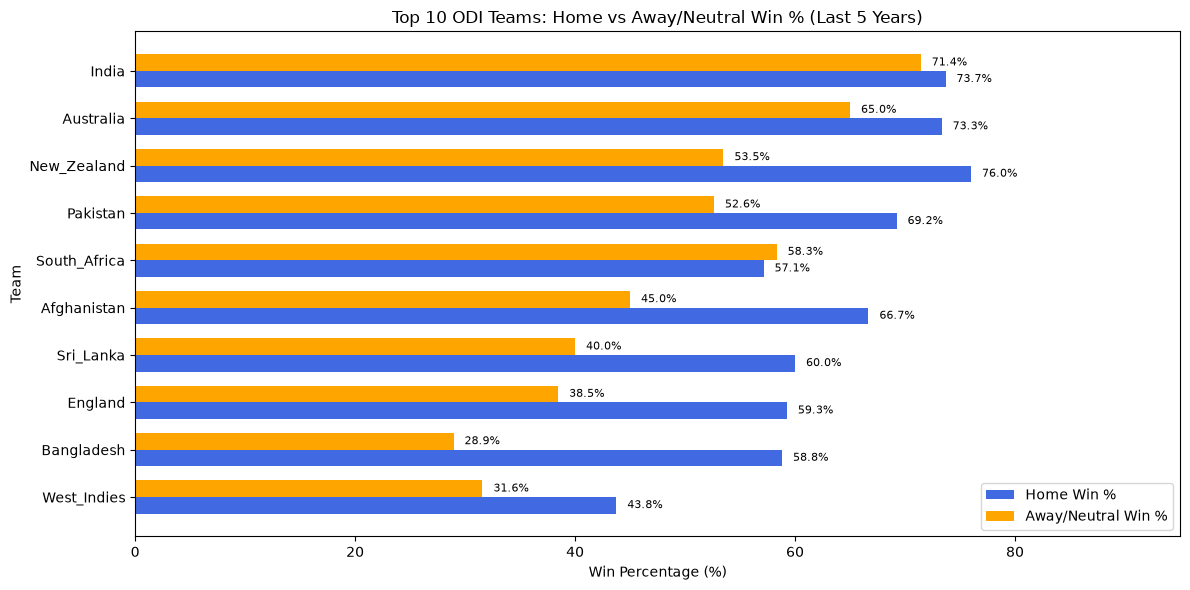

In [2]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

csv_data = """Team,Current_Rank,Home_Matches,Home_W,Home_L,Home_Tie_NR,Home_Win_Pct,Away_Matches,Away_W,Away_L,Away_Tie_NR,Away_Win_Pct,Total_5Y_Matches,Total_5Y_W,Total_5Y_L,Total_5Y_Tie_NR,Overall_5Y_Win_Pct
India,1,38,28,9,1,73.68,42,30,10,2,71.43,80,58,19,3,72.50
Australia,2,30,22,7,1,73.33,40,26,13,1,65.00,70,48,20,2,68.57
South_Africa,3,28,16,11,1,57.14,36,21,13,2,58.33,64,37,24,3,57.81
Pakistan,4,26,18,7,1,69.23,38,20,17,1,52.63,64,38,24,2,59.38
New_Zealand,5,25,19,5,1,76.00,43,23,18,2,53.49,68,42,23,3,61.76
Sri_Lanka,6,35,21,12,2,60.00,45,18,25,2,40.00,80,39,37,4,48.75
England,7,27,16,9,2,59.26,39,15,22,2,38.46,66,31,31,4,46.97
Afghanistan,8,12,8,4,0,66.67,40,18,20,2,45.00,52,26,24,2,50.00
Bangladesh,9,34,20,13,1,58.82,38,11,25,2,28.95,72,31,38,3,43.06
West_Indies,10,32,14,17,1,43.75,38,12,24,2,31.58,70,26,41,3,37.14"""

df = pd.read_csv(io.StringIO(csv_data))
df_sorted = df.sort_values(by='Overall_5Y_Win_Pct', ascending=True)

plt.figure(figsize=(12, 6))
x = np.arange(len(df_sorted['Team']))
width = 0.35

plt.barh(x - width/2, df_sorted['Home_Win_Pct'], width, label='Home Win %', color='royalblue')
plt.barh(x + width/2, df_sorted['Away_Win_Pct'], width, label='Away/Neutral Win %', color='orange')

for i in range(len(df_sorted)):
    plt.text(df_sorted['Home_Win_Pct'].iloc[i] + 1, i - width/2, f"{df_sorted['Home_Win_Pct'].iloc[i]:.1f}%", va='center', fontsize=8)
    plt.text(df_sorted['Away_Win_Pct'].iloc[i] + 1, i + width/2, f"{df_sorted['Away_Win_Pct'].iloc[i]:.1f}%", va='center', fontsize=8)

plt.yticks(x, df_sorted['Team'])
plt.xlabel('Win Percentage (%)')
plt.ylabel('Team')
plt.title('Top 10 ODI Teams: Home vs Away/Neutral Win % (Last 5 Years)')
plt.xlim(0, 95)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('home_vs_away_win_percentage.png')
plt.show()